# Model explainability with SHAP

Explain the selected LightGBM model without retraining and save explanations in a separate MLflow run.

In [1]:
START_DATE = "2022-01-01"
END_DATE = "2026-10-18"
INPUT_FILE = f"data/processed/dataset_{START_DATE}_{END_DATE}.parquet"
TRACKING_URI = "http://127.0.0.1:5001"
TRAINING_RUN_ID = "e26b009c294b4adb9521ab46d85955e4"
MODEL_URI = "models:/m-0eed3692206b4f9d8b3d82ac6dcca89c"
SAMPLE_SIZE = 2000
SEED = 42

In [2]:
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from lightgbm import LGBMRegressor
from mlflow import sklearn as mlflow_sklearn
from mlflow.artifacts import load_dict
from mlflow.environment_variables import MLFLOW_ENABLE_PROXY_MULTIPART_DOWNLOAD
from mlflow.models import get_model_info

ROOT = Path.cwd().parent
DATA_PATH = ROOT / INPUT_FILE
plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": False})
figures = {}

## Load the exact model and feature contract

The IDs refer to the final 2026 test run from notebook 04. Update both IDs together if you select another model. The logged model predicts capacity factor, not MW.

Download artifacts through MLflow rather than signed URLs pointing to the Docker-internal S3 endpoint.

In [3]:
MLFLOW_ENABLE_PROXY_MULTIPART_DOWNLOAD.set(False)
mlflow.set_tracking_uri(TRACKING_URI)
client = mlflow.MlflowClient()
training_run = client.get_run(TRAINING_RUN_ID)
model_info = get_model_info(MODEL_URI)
assert model_info.run_id == TRAINING_RUN_ID
model = mlflow_sklearn.load_model(MODEL_URI)
assert isinstance(model, LGBMRegressor)
contract = load_dict(f"runs:/{TRAINING_RUN_ID}/features.json")
FEATURES = contract["features"]
TARGET = contract["target"]
assert FEATURES == model.feature_name_
print("Model:", MODEL_URI)
print(
    "Training window:",
    training_run.data.params["train_start"],
    "to",
    training_run.data.params["train_end"],
)
print("Features:", len(FEATURES))

Model: models:/m-0eed3692206b4f9d8b3d82ac6dcca89c
Training window: 2025-01-01 00:00:00+00:00 to 2025-12-31 23:00:00+00:00
Features: 33


## Read the saved training table

Require the same Parquet file used by the training run. No downloading or feature preparation is performed here.

In [4]:
DATA_HASH = sha256(DATA_PATH.read_bytes()).hexdigest()
assert DATA_HASH == training_run.data.params["dataset_sha256"], (
    "Dataset differs from the training run"
)
dataset = pd.read_parquet(DATA_PATH).sort_values("timestamp_utc").reset_index(drop=True)
dataset["timestamp_utc"] = pd.to_datetime(dataset.timestamp_utc, utc=True).dt.as_unit(
    "ns"
)
assert not dataset.timestamp_utc.duplicated().any()
assert np.isfinite(dataset[[*FEATURES, TARGET]].to_numpy()).all()
assert dataset.installed_pv_capacity_mw.gt(0).all()

## Select the evaluation interval

Use the interval recorded in the source run. This is post-test diagnosis; do not use these explanations to tune the model and still call 2026 an untouched test.

In [5]:
evaluation = dataset.loc[
    dataset.timestamp_utc.between(
        pd.Timestamp(training_run.data.params["evaluation_start"]),
        pd.Timestamp(training_run.data.params["evaluation_end"]),
    )
].copy()
assert len(evaluation) == int(training_run.data.params["evaluation_rows"])
evaluation["prediction_cf"] = np.asarray(model.predict(evaluation[FEATURES]))
evaluation["prediction_mw"] = (
    evaluation.prediction_cf * evaluation.installed_pv_capacity_mw
)
evaluation["error_mw"] = (
    evaluation.prediction_mw - evaluation.target_solar_generation_mw
)
sample = evaluation.sample(
    n=min(SAMPLE_SIZE, len(evaluation)), random_state=SEED
).sort_values("timestamp_utc")
X = sample[FEATURES]
daylight = sample.solar_elevation_max.gt(0).to_numpy()
assert daylight.any()
print(
    f"Evaluation hours: {len(evaluation):,}; explained sample: {len(sample):,}; daylight sample: {daylight.sum():,}"
)

Evaluation hours: 6,984; explained sample: 2,000; daylight sample: 1,094


## Compute SHAP values

Tree-path-dependent SHAP uses the training path counts stored in the model and needs no separate background sample. Contributions explain raw capacity factor relative to the expected model output. Verify that baseline plus contributions reconstructs each prediction.

In [6]:
explainer = shap.TreeExplainer(
    model, feature_perturbation="tree_path_dependent", model_output="raw"
)
shap_values = explainer(X)
contribution_values = np.asarray(shap_values.values)
np.testing.assert_allclose(
    shap_values.base_values + contribution_values.sum(axis=1),
    sample.prediction_cf.to_numpy(),
    rtol=1e-5,
    atol=1e-7,
)
importance = pd.DataFrame(
    {
        "feature": FEATURES,
        "mean_abs_shap_cf": np.abs(contribution_values).mean(axis=0),
        "day_mean_abs_shap_cf": np.abs(contribution_values[daylight]).mean(axis=0),
    }
).sort_values("mean_abs_shap_cf", ascending=False)
display(importance)

,feature,mean_abs_shap_cf,day_mean_abs_shap_cf
17,clear_sky_ghi_max,0.051126,0.062780
26,weather_shortwave_radiation_mean,0.024328,0.029879
16,solar_elevation_max,0.018800,0.022729
1,hour_local,0.014790,0.020463
24,weather_direct_radiation_mean,0.012293,0.014171
8,hour_cos,0.004571,0.005095
21,weather_cloud_cover_low_mean,0.002818,0.003831
11,solar_elevation_mean,0.002643,0.003294
25,weather_precipitation_mean,0.002174,0.003071
19,weather_cloud_cover_mean,0.001879,0.002699


## Global feature importance

Mean absolute SHAP measures the magnitude of contributions, not their direction. Compare all sampled hours with daylight hours so shared night-time zeros do not dominate the interpretation.

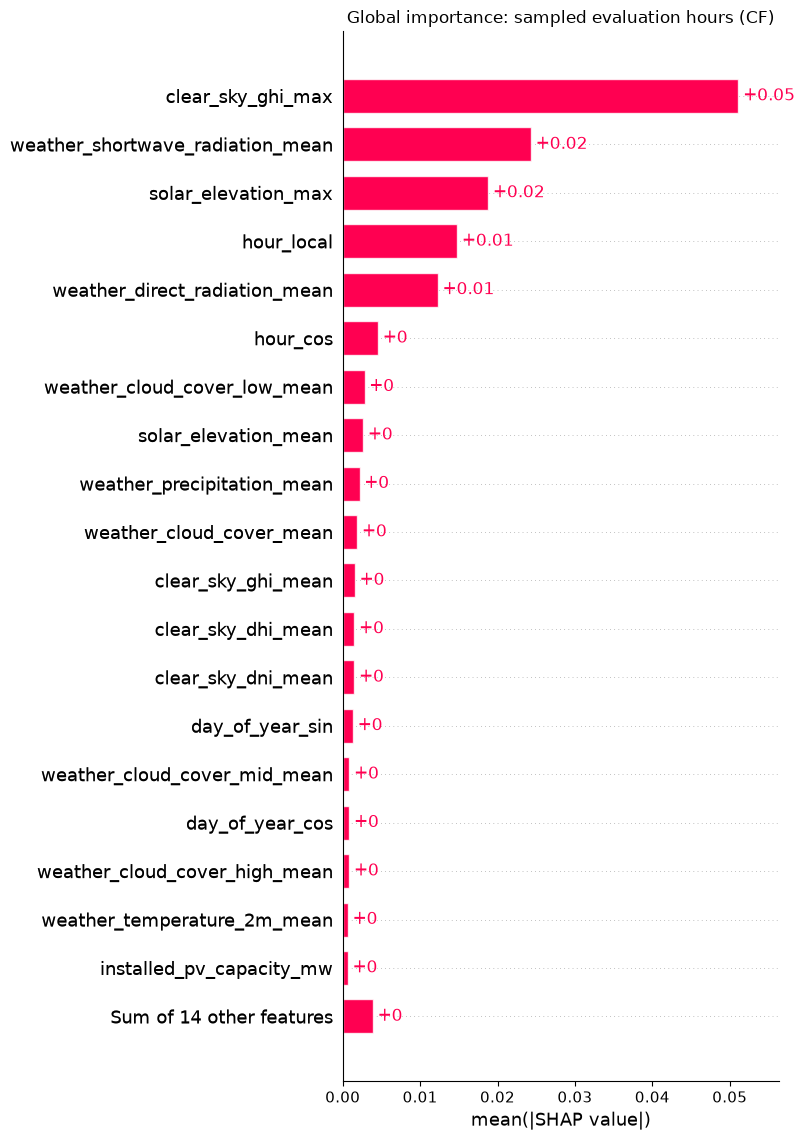

In [7]:
shap.plots.bar(shap_values, max_display=20, show=False)
figures["importance_all.png"] = plt.gcf()
plt.title("Global importance: sampled evaluation hours (CF)")
plt.tight_layout()
plt.show()
plt.close()

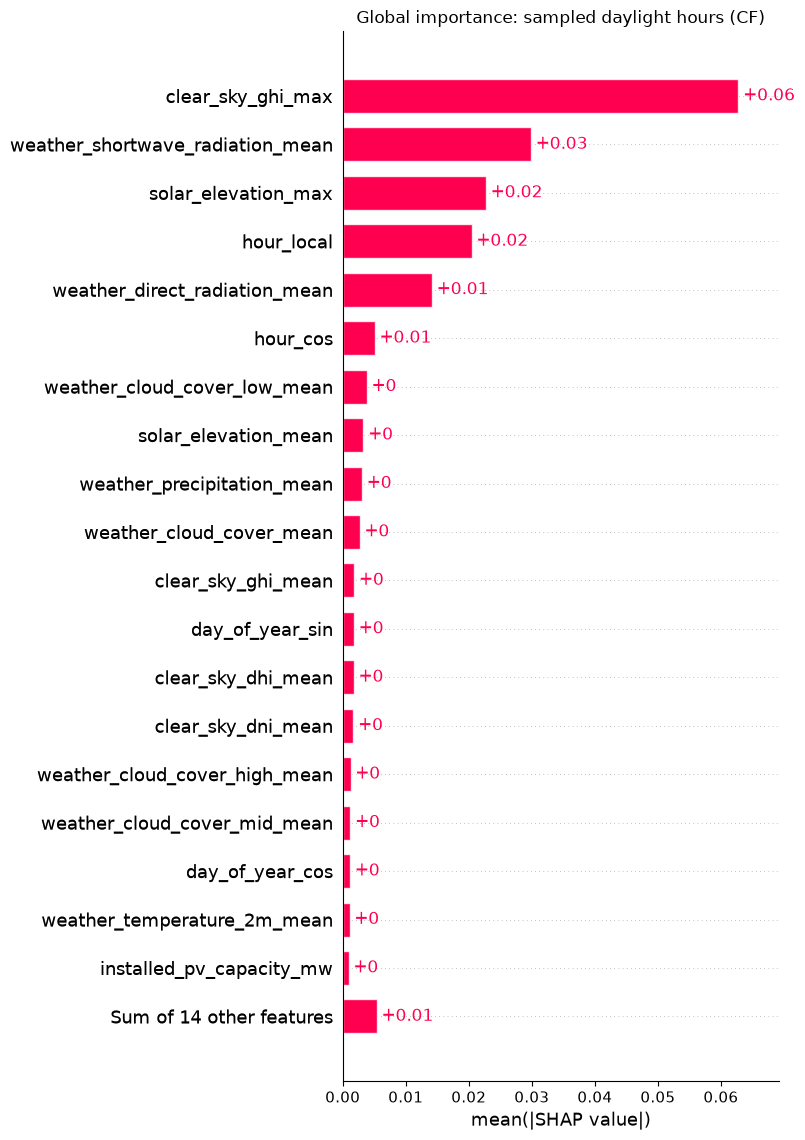

In [8]:
shap.plots.bar(shap_values[daylight], max_display=20, show=False)
figures["importance_daylight.png"] = plt.gcf()
plt.title("Global importance: sampled daylight hours (CF)")
plt.tight_layout()
plt.show()
plt.close()

## Direction of feature effects

Positive SHAP values increase predicted CF relative to the baseline; negative values decrease it. Colors show feature values. Correlated radiation and solar features can share attribution, so this is not causal evidence.

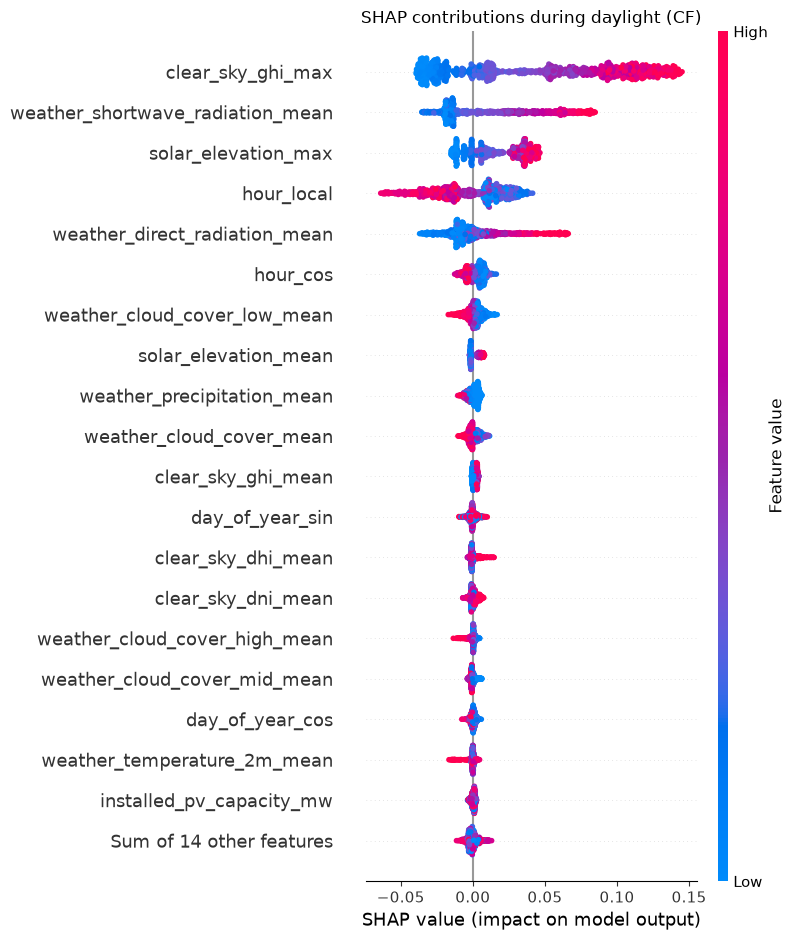

In [9]:
shap.plots.beeswarm(shap_values[daylight], max_display=20, show=False)
figures["beeswarm_daylight.png"] = plt.gcf()
plt.title("SHAP contributions during daylight (CF)")
plt.tight_layout()
plt.show()
plt.close()

## Radiation and cloud-cover effects

Inspect nonlinear relationships and how they vary with solar elevation or radiation.

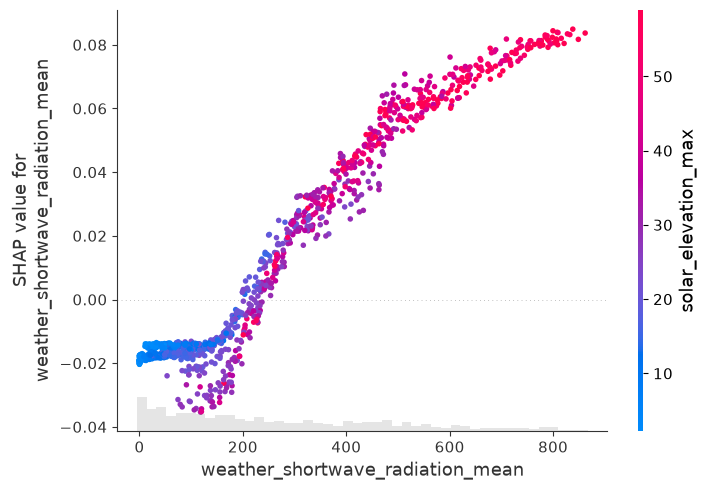

In [10]:
shap.plots.scatter(
    shap_values[daylight, "weather_shortwave_radiation_mean"],
    color=shap_values[daylight, "solar_elevation_max"],
    show=False,
)
figures["radiation_effect.png"] = plt.gcf()
plt.tight_layout()
plt.show()
plt.close()

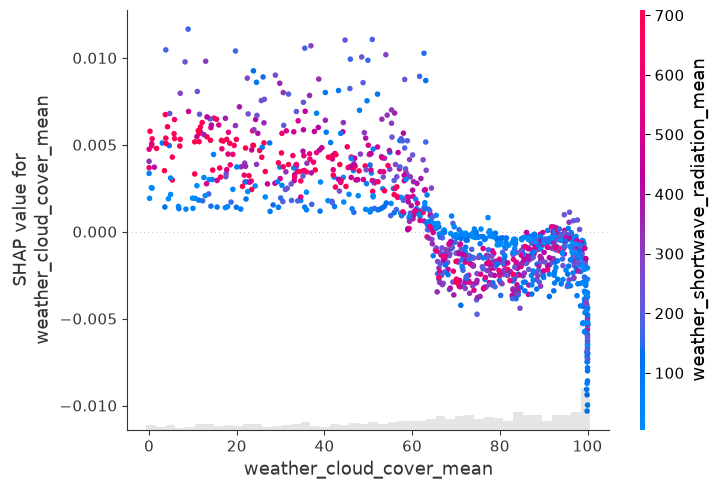

In [11]:
shap.plots.scatter(
    shap_values[daylight, "weather_cloud_cover_mean"],
    color=shap_values[daylight, "weather_shortwave_radiation_mean"],
    show=False,
)
figures["cloud_effect.png"] = plt.gcf()
plt.tight_layout()
plt.show()
plt.close()

## Explain individual forecasts

Select a representative daylight forecast, the largest daylight absolute error, and the lowest prediction across the evaluation interval. These cases are diagnostic examples, not a representative sample. Waterfalls explain predictions in CF; MW values use the recorded capacity.

In [12]:
day = evaluation.loc[evaluation.solar_elevation_max.gt(0)]
assert not day.empty
cases = {
    "typical_daylight": (day.prediction_cf - day.prediction_cf.median()).abs().idxmin(),
    "largest_daylight_error": day.error_mw.abs().idxmax(),
    "lowest_prediction": evaluation.prediction_cf.idxmin(),
}
case_rows = evaluation.loc[list(cases.values())].copy()
case_rows.insert(0, "case", list(cases))
local_values = explainer(case_rows[FEATURES])
np.testing.assert_allclose(
    local_values.base_values + np.asarray(local_values.values).sum(axis=1),
    case_rows.prediction_cf.to_numpy(),
    rtol=1e-5,
    atol=1e-7,
)
CASE_COLUMNS = [
    "case",
    "timestamp_utc",
    TARGET,
    "prediction_cf",
    "installed_pv_capacity_mw",
    "target_solar_generation_mw",
    "prediction_mw",
    "error_mw",
]
display(case_rows[CASE_COLUMNS])

,case,timestamp_utc,target_solar_capacity_factor,prediction_cf,installed_pv_capacity_mw,target_solar_generation_mw,prediction_mw,error_mw
35892,typical_daylight,2026-02-04 12:00:00+00:00,0.101191,0.161293,106050.909133,10731.43,17105.217238,6373.787238
35315,largest_daylight_error,2026-01-11 11:00:00+00:00,0.077055,0.199789,105035.481576,8093.56,20984.891817,12891.331817
40099,lowest_prediction,2026-07-29 19:00:00+00:00,0.001151,-0.007535,113254.206797,130.30,-853.388358,-983.688358


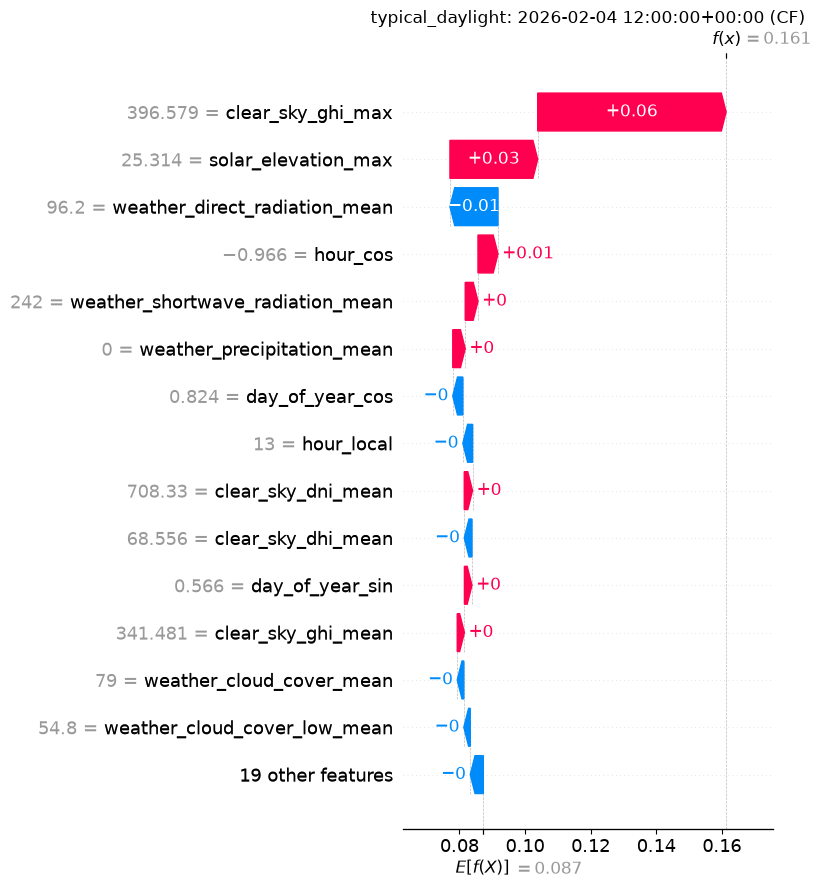

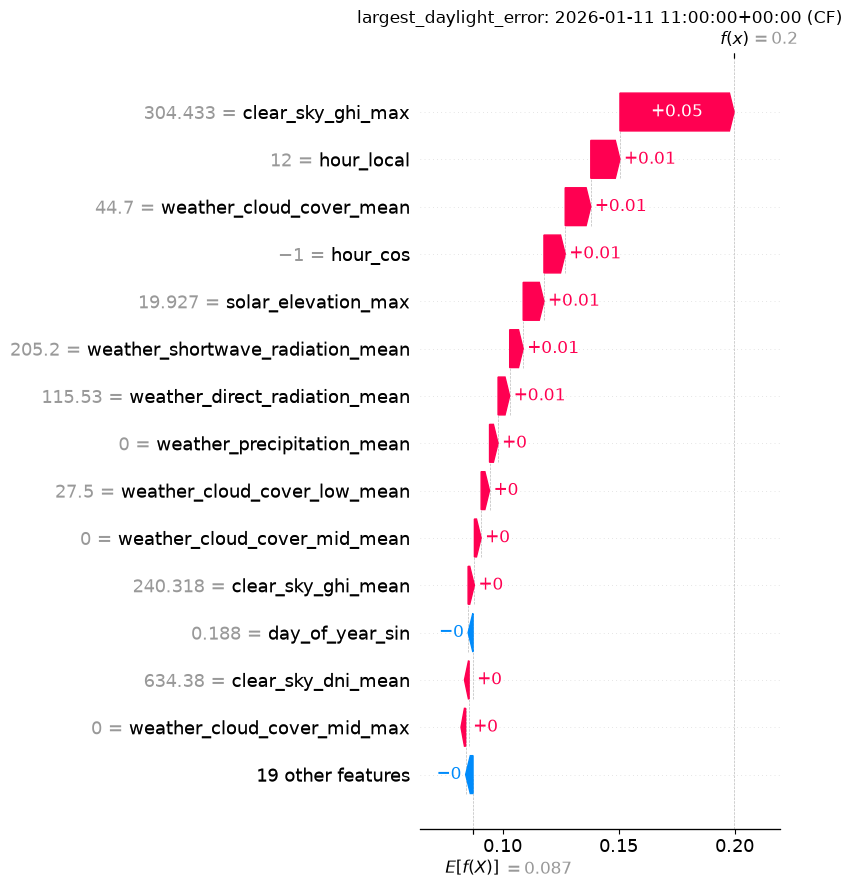

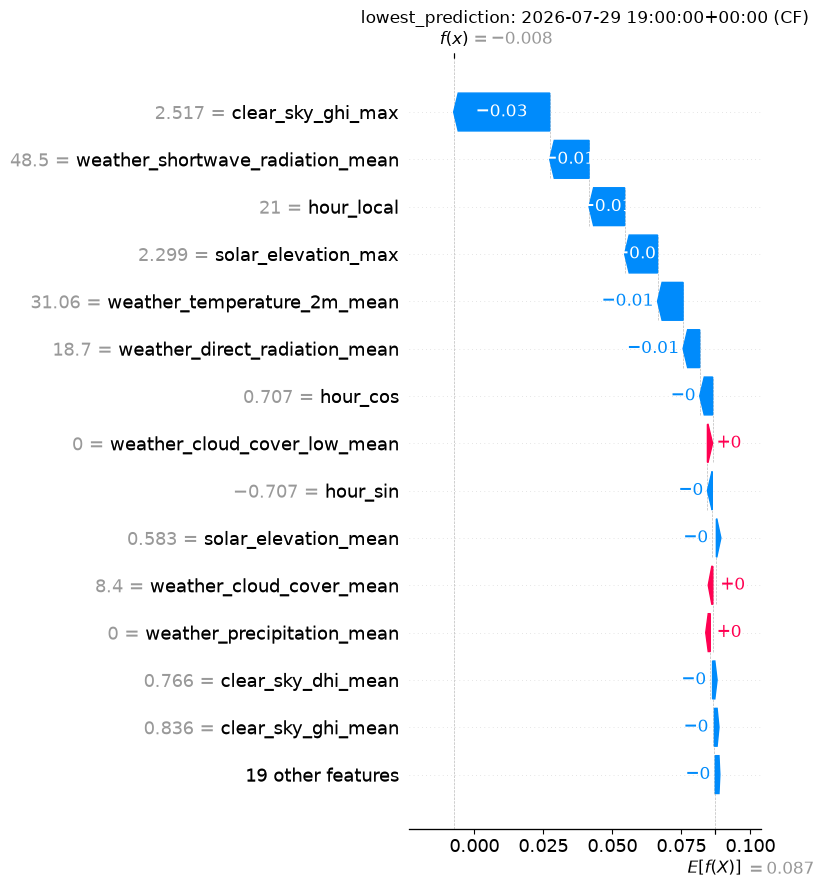

In [13]:
for i, name in enumerate(cases):
    shap.plots.waterfall(local_values[i], max_display=15, show=False)
    figures[f"waterfall_{name}.png"] = plt.gcf()
    plt.title(f"{name}: {case_rows.iloc[i].timestamp_utc} (CF)")
    plt.tight_layout()
    plt.show()
    plt.close()

## Save explanations to MLflow

Create a separate run in the same experiment, linked to the source training run. Preserve timestamps, feature values, baselines, and contributions so explanations can be inspected again. This does not retrain or register a model.

In [14]:
contributions = pd.DataFrame(contribution_values, columns=FEATURES)
contributions.insert(0, "timestamp_utc", sample.timestamp_utc.to_numpy())
contributions["base_value_cf"] = shap_values.base_values
contributions["prediction_cf"] = sample.prediction_cf.to_numpy()
local_contributions = pd.DataFrame(local_values.values, columns=FEATURES)
local_contributions.insert(0, "case", list(cases))
local_contributions["base_value_cf"] = local_values.base_values

with mlflow.start_run(
    experiment_id=training_run.info.experiment_id, run_name="shap_explainability"
) as run:
    mlflow.set_tags({"source_training_run_id": TRAINING_RUN_ID, "analysis": "SHAP"})
    mlflow.log_params(
        {
            "model_uri": MODEL_URI,
            "dataset_sha256": DATA_HASH,
            "sample_size": len(sample),
            "daylight_sample_size": int(daylight.sum()),
            "seed": SEED,
            "shap_version": shap.__version__,
            "feature_perturbation": "tree_path_dependent",
            "output_unit": "capacity_factor",
        }
    )
    mlflow.log_dict(contract, "features.json")
    mlflow.log_text(importance.to_csv(index=False), "importance.csv")
    mlflow.log_text(
        sample[["timestamp_utc", *FEATURES]].to_csv(index=False), "sample_features.csv"
    )
    mlflow.log_text(contributions.to_csv(index=False), "shap_values.csv")
    mlflow.log_text(
        case_rows[CASE_COLUMNS].to_csv(index=False), "local_predictions.csv"
    )
    mlflow.log_text(
        case_rows[["case", "timestamp_utc", *FEATURES]].to_csv(index=False),
        "local_features.csv",
    )
    mlflow.log_text(local_contributions.to_csv(index=False), "local_shap_values.csv")
    for name, figure in figures.items():
        mlflow.log_figure(figure, name)
    print("SHAP run ID:", run.info.run_id)

SHAP run ID: 49cfd8e5c2024c54b4859cede0f58bbb
🏃 View run shap_explainability at: http://127.0.0.1:5001/#/experiments/3/runs/49cfd8e5c2024c54b4859cede0f58bbb
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


SHAP describes this model and this evaluation sample. It does not establish causal effects, validate historical forecast availability, or explain errors as a separate loss model. Changes motivated by test-period explanations need a new future holdout.